# Group theory 3: Permutations and Lagrange's theorem

*Learning path: group theory, part 3 of 3.* [Index](README.md) · Previous: [Cyclic groups](02-cyclic-groups.ipynb)

Every finite group can be found inside a group of permutations (Cayley's theorem), so permutations are the universal
laboratory of group theory. This lesson works with them and proves the first real theorem of the subject. You will
learn

* the **symmetric group** $S_n$ and its $n!$ elements,
* how cycle notation gives the order of a permutation, and why 8 perfect shuffles restore a deck of cards,
* **even and odd** permutations, and why Sam Loyd's 15 puzzle prize was never claimed,
* **cosets** and **Lagrange's theorem**: the size of a subgroup divides the size of the group,
* Fermat's little theorem as a one-line consequence.

## 1. The symmetric group

All permutations of $1, \ldots, n$ form a group, the **symmetric group** $S_n$. It has $n!$ elements: $n$ choices for
where 1 goes, $n - 1$ for 2, and so on. Two well-chosen permutations generate it all: a full cycle and one swap. `size`
gives rows and columns of the list `generate` produces, so the first number is the size of the group:

In [1]:
size(generate(perm("(1 2 3)", 3), perm("(1 2)", 3)))
size(generate(perm("(1 2 3 4)", 4), perm("(1 2)", 4)))
size(generate(perm("(1 2 3 4 5)", 5), perm("(1 2)", 5)))
factorial(5)

6	3
24	4
120	5
120

## 2. Cycles and orders

Any permutation splits into disjoint cycles. `perm("(1 2 3)(4 5)", 5)` sends $1 \to 2 \to 3 \to 1$ and swaps 4 and 5.
The 3-cycle comes back after 3 steps, the swap after 2, so the whole permutation comes back after the least common
multiple, $\operatorname{lcm}(3, 2) = 6$ steps. That is its order:

In [2]:
p = perm("(1 2 3)(4 5)", 5)
porder(p)
lcm(3, 2)

2	3	1	5	4
6
6

### Perfect shuffles

A **perfect out-shuffle** cuts a deck of $2n$ cards exactly in half and interleaves them perfectly, with the top card
staying on top. The card at position $i$ moves to position $2i - 1$ if it was in the top half ($i \le n$) and to
$2(i - n)$ if it was in the bottom half. `table(..., i, 1, 2*n)` lists these new positions, one per card, in a row: exactly
the one-line notation of a permutation that `porder` expects. `out(n)` is the order of the out-shuffle
of $2n$ cards, the number of shuffles that bring the deck back to its starting order:

In [3]:
out(n) := porder(table(if(i <= n, 2*i - 1, 2*(i - n)), i, 1, 2*n));
out(26)

8

**Eight** perfect shuffles restore a deck of 52 cards, a classic magician's trick. Here is its cycle structure: six
cycles of length 8, one of length 2 (cards 18 and 35 swap places), and the top and bottom cards, which never move:

In [4]:
cycles(table(if(i <= 26, 2*i - 1, 2*(i - 26)), i, 1, 52))

(2 3 5 9 17 33 14 27)(4 7 13 25 49 46 40 28)(6 11 21 41 30 8 15 29)(10 19 37 22 43 34 16 31)(12 23 45 38 24 47 42 32)(18 35)(20 39 26 51 50 48 44 36)

Why 8? Ignoring the bottom card, the out-shuffle sends the card at position $j = i - 1$ (counting from 0) to position
$2j \bmod (2n - 1)$: doubling mod $2n - 1$. So the order is the order of 2 mod $2n - 1$, from number theory lesson 3.
For 52 cards, $2^8 = 256 = 5\cdot51 + 1$. The table compares the deck size, the order of the shuffle and
`multorder(2, 2n - 1)`:

In [5]:
table([2*n, out(n), multorder(2, 2*n - 1)], n, 2, 12)
multorder(2, 51)

4	2	2
6	4	4
8	3	3
10	6	6
12	10	10
14	12	12
16	4	4
18	8	8
20	18	18
22	6	6
24	11	11
8

The plot shows the order for every deck size from 4 to 120 cards: across the number of cards, up the number of
out-shuffles that restore the deck. Some decks come back quickly (64 cards: 6 shuffles, since $2^6 = 64 \equiv 1$ mod
63), others take as many shuffles as there are cards minus 2:

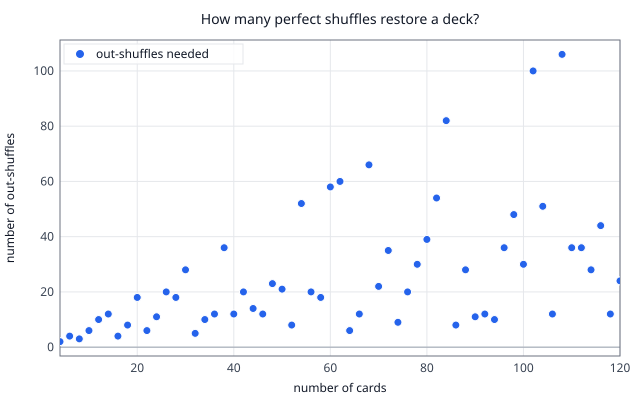

In [6]:
S = table([2*n, out(n)], n, 2, 60);
labels(title(legend(scatter(S, [cards order]), "out-shuffles needed"), "How many perfect shuffles restore a deck?"), "number of cards", "number of out-shuffles")

## 3. Even and odd

Every permutation can be written as a product of swaps (transpositions), in many ways. But the number of swaps is
always even or always odd for a given permutation, and `psign` gives $+1$ for **even** and $-1$ for **odd**. A cycle
of length $k$ takes $k - 1$ swaps, so a 3-cycle is even and a swap is odd:

In [7]:
psign(perm("(1 2 3)", 3))
psign(perm("(1 2)", 3))
psign(perm("(1 2 3)(4 5)", 5))

1
-1
-1

The sign of a product is the product of the signs, so the even permutations form a subgroup, the **alternating group**
$A_n$, with half the elements: $n!/2$. The 3-cycles $(1\ 2\ 3)$ and $(1\ 2)(3\ 4)$ generate $A_4$:

In [8]:
A4 = generate(perm("(1 2 3)", 4), perm("(1 2)(3 4)", 4));
size(A4)

12	4

### The 15 puzzle

The 15 puzzle has tiles 1 to 15 and one empty square in a 4 by 4 frame; a move slides a tile into the empty square. In
1880 Sam Loyd offered \$1000 to anyone who could swap tiles 14 and 15 and leave everything else in place. Think of the
empty square as tile 16. Every move swaps tile 16 with a neighbour, which is one transposition. To bring the empty
square back to its corner it must move left as often as right and up as often as down: an even number of moves. So
every reachable position, with the empty square home, is an even permutation. Swapping 14 and 15 is odd:

In [9]:
psign(perm("(14 15)", 16))

-1

Impossible, and the prize was safe. (Exactly half of the $16!$ arrangements are reachable.)

## 4. Cosets and Lagrange's theorem

In lesson 1 the rotations $H = \{e, r, r^2\}$ formed a subgroup of the triangle's group $G = S_3$. Take any element $g$
of $G$ and compose it with every element of $H$: the result $gH$ is a **coset**. For $g$ = the flip $(2\ 3)$, the second
element of $G$:

In [10]:
G = generate(perm("(1 2 3)", 3), perm("(2 3)", 3));
H = generate(perm("(1 2 3)", 3))
g = G(2)
table(compose(g, H(k)), k, 1, 3)

1	2	3
2	3	1
3	1	2
1	3	2
1	3	2
3	2	1
2	1	3

`H(k)` is the $k$-th element of $H$, so the table lists $g$ after each element of $H$, one per row. The coset $gH$
consists of the three flips. So $G$ splits into two cosets of $H$: the rotations ($H$ itself, the coset of the
identity) and the flips.

This always happens. For a subgroup $H$ of a finite group $G$:

1. each coset $gH$ has exactly as many elements as $H$ (composing with $g$ can be undone, so no two elements collapse);
2. two cosets are either equal or have no element in common (if $gh_1 = g'h_2$ then $g' = gh_1h_2^{-1}$, so
   $g'H = gH$);
3. every $g$ lies in its own coset $gH$.

So the cosets cut $G$ into pieces of equal size $|H|$, and **Lagrange's theorem** follows (1771, in a form about
polynomials; in this form by Galois and Cauchy):

$$|H| \text{ divides } |G|.$$

The same for the subgroup of rotations $\{e, s, s^2, s^3\}$ of the square inside $S_4$: $24/4 = 6$ cosets.

In [11]:
size(generate(perm("(1 2 3 4)", 4)))
24/4

4	4
6

### Consequences

The powers of any element $a$ form a cyclic subgroup whose size is the order of $a$. So **the order of every element
divides the size of the group**: $a^{|G|} = e$ always.

Apply this to the group $U(p) = \{1, \ldots, p - 1\}$ under multiplication mod a prime $p$ (lesson 2). It has $p - 1$
elements, so $a^{p-1} \equiv 1 \pmod p$ for every $a$: **Fermat's little theorem**, in one line. For $U(n)$ with
$\varphi(n)$ elements it gives Euler's theorem $a^{\varphi(n)} \equiv 1$, the engine of RSA.

In [12]:
powmod(5, 100, 101)
powmod(7, totient(36), 36)

1
1

### The converse fails

Lagrange does not promise a subgroup for every divisor. $A_4$ has 12 elements but no subgroup of size 6. A group of
size 6 is generated by two of its elements, so it is enough to try every pair. `rows(G)` counts the rows of a list,
that is, the elements of a group. `sz(i, j)` is the size of the group generated by elements $i$ and $j$ of $A_4$, and
the table has one row per $i$ and one column per $j$ (a table of tables):

In [13]:
sz(i, j) := rows(generate(A4(i), A4(j)));
table(table(sz(i, j), j, 1, 12), i, 1, 12)

1	3	3	2	3	3	3	3	2	3	3	2
3	3	3	12	12	12	12	12	12	12	12	12
3	3	3	12	12	12	12	12	12	12	12	12
2	12	12	2	12	12	12	12	4	12	12	4
3	12	12	12	3	12	3	12	12	12	12	12
3	12	12	12	12	3	12	12	12	3	12	12
3	12	12	12	3	12	3	12	12	12	12	12
3	12	12	12	12	12	12	3	12	12	3	12
2	12	12	4	12	12	12	12	2	12	12	4
3	12	12	12	12	3	12	12	12	3	12	12
3	12	12	12	12	12	12	3	12	12	3	12
2	12	12	4	12	12	12	12	4	12	12	2

Only the sizes 1, 2, 3, 4 and 12 appear: never 6, although 6 divides 12.

Where this leads: Sylow's theorems (1872) say which subgroup sizes *must* exist; Galois used the structure of $S_5$
(its only proper normal subgroup $A_5$ is "simple") to show that degree-5 equations have no formula in radicals; and
the Rubik's cube group, a subgroup of $S_{48}$, has $43\,252\,003\,274\,489\,856\,000$ elements. That count is
$8!\cdot 3^7$ (the corners: their positions and twists, the last twist fixed by the others) times $12!\cdot 2^{11}$
(the edges, likewise) divided by 2 (corner and edge permutations are both even or both odd). By Lagrange it divides
$|S_{48}| = 48!$, a 62-digit number:

In [14]:
cube = factorial(8)*3^7*factorial(12)*2^11/2
factor(cube)
factorial(48)
factorial(48)/cube

43252003274489856000
2^27 * 3^14 * 5^3 * 7^2 * 11
12413915592536072670862289047373375038521486354677760000000000
287013656078626822064321228804136960000000

## Summary

* $S_n$ has $n!$ elements and is generated by a full cycle and a swap.
* The order of a permutation is the lcm of its cycle lengths (`porder`, `cycles`). Perfect out-shuffles of $2n$ cards:
  order of 2 mod $2n - 1$; 8 for 52 cards.
* Even and odd permutations (`psign`); the even ones form $A_n$. The 15 puzzle cannot swap two tiles.
* Cosets $gH$ split $G$ into equal pieces: $|H|$ divides $|G|$ (Lagrange). Hence orders divide $|G|$, and Fermat's and
  Euler's theorems.

**Try it:** an in-shuffle keeps the top card second instead of first (position $i \to 2i$ for the top half, $2(i - n)
- 1$ for the bottom half). How many in-shuffles restore 52 cards? Find the cosets of the subgroup
$\{e, (1\ 2)\}$ in $S_3$: are $gH$ and $Hg$ always the same?

This is the end of the group theory path. See also [number theory](../number-theory/README.md), where these groups do
the work in cryptography.

## Sources

1. J.-L. Lagrange, "Réflexions sur la résolution algébrique des équations", *Nouveaux Mémoires de l'Académie Royale de Berlin* (1770–1771).
2. A. Cayley, "On the theory of groups, as depending on the symbolic equation θⁿ = 1", *Philosophical Magazine* 7 (1854) 40–47.
3. W. W. Johnson and W. E. Story, "Notes on the '15' puzzle", *American Journal of Mathematics* 2 (1879) 397–404.
4. P. Diaconis, R. L. Graham and W. M. Kantor, "The mathematics of perfect shuffles", *Advances in Applied Mathematics* 4 (1983) 175–196.
5. J. A. Gallian, *Contemporary Abstract Algebra*, 9th ed., Cengage (2017). Chapters 5 and 7.